# Kiểm định giả thuyết H1–H4

- **[P]** (danh sách xe, 134,726 dòng): H1 (Mann–Whitney U), H2 (Spearman), H3 (chi-square CAFV), H4a (chi-square County × loại xe).
- **[H]** (số xe theo county theo tháng): H4b (chi-square đồng nhất tỷ lệ EV).

Mức ý nghĩa α = 0.05. Logic nằm trong `src/hypothesis_tests_P.py` và `src/hypothesis_tests_H.py`; notebook này gọi lại các hàm đó và vẽ biểu đồ.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import hypothesis_tests_P as tp
import hypothesis_tests_H as th

(ROOT / "figures").mkdir(exist_ok=True)
print("ROOT =", ROOT)

ROOT = D:\Giang\IS403\IS403_repo\washington-ev-analysis-forecasting


## Dataset [P]: H1, H2, H3, H4a

In [2]:
P = tp.load()
print(f"{len(P):,} dòng | Range thiếu: {P[tp.RANGE].isna().sum():,} | số county: {P[tp.COUNTY].nunique()}")
tp.h1(P)
tp.h2(P)
tp.h3(P)
tp.h4a(P)

134,726 dòng | Range thiếu: 56,869 | số county: 39

=== H1: Electric Range theo loại xe | n có Range = 77,857 (thiếu 56,869) ===
[H1 chính, toàn mẫu có Range] n_BEV=46,806 n_PHEV=31,051 | median BEV=215, PHEV=26 | U=1,446,940,030 p=0 | rank-biserial=0.991 | xác suất ưu thế=0.996 -> Bác bỏ H0
[H1 độ nhạy, Model Year<=2020] n_BEV=46,323 n_PHEV=19,456 | median BEV=215, PHEV=25 | U=895,028,844 p=0 | rank-biserial=0.986 | xác suất ưu thế=0.993 -> Bác bỏ H0

=== H2: Model Year vs Electric Range ===
[H2 chính, toàn mẫu] n=77,857 rho=0.090 |rho|=0.090 p=5.51e-140 -> Bác bỏ H0
[H2 BEV] n=46,806 rho=0.780 |rho|=0.780 p=0 -> Bác bỏ H0
[H2 PHEV] n=31,051 rho=0.036 |rho|=0.036 p=3.76e-10 -> Bác bỏ H0

=== H3: Loại xe x CAFV Eligibility ===
Nhãn unknown: 56,868 dòng | trùng với Range thiếu: 56,868 | thuộc BEV: 56,868


Clean Alternative Fuel Vehicle (CAFV) Eligibility  Clean Alternative Fuel Vehicle Eligible  \
Type                                                                                         
BEV                                                                                  46796   
PHEV                                                                                 14287   

Clean Alternative Fuel Vehicle (CAFV) Eligibility  Not eligible due to low battery range  
Type                                                                                      
BEV                                                                                   10  
PHEV                                                                               16765  
[H3 chính 2x2, bỏ unknown] bảng 2x2 n=77,858 chi2=32,165.89 dof=1 p=0 Cramér's V=0.643 | min E=6,690.4 -> Bác bỏ H0
Clean Alternative Fuel Vehicle (CAFV) Eligibility  Clean Alternative Fuel Vehicle Eligible  \
Type                                             

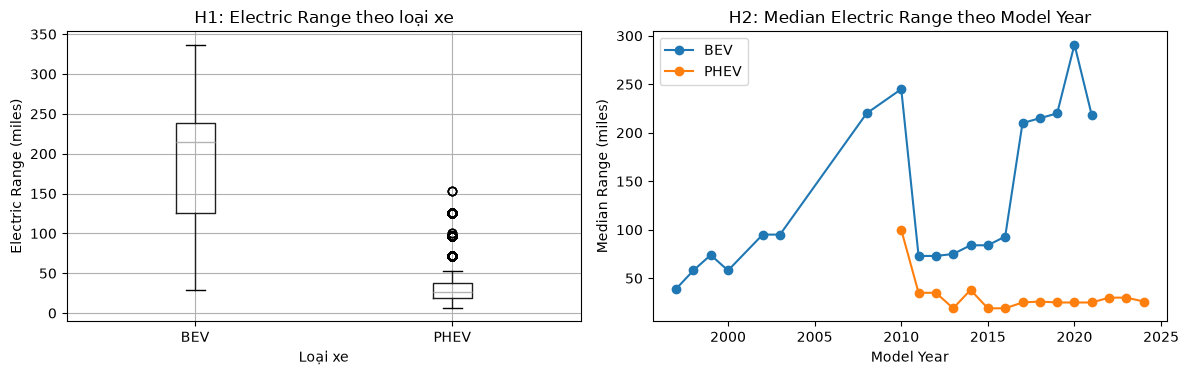

In [3]:
d = P.dropna(subset=[tp.RANGE])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
d.boxplot(column=tp.RANGE, by="Type", ax=ax[0])
ax[0].set(title="H1: Electric Range theo loại xe", xlabel="Loại xe", ylabel="Electric Range (miles)")
for t, g in d.groupby("Type"):
    ax[1].plot(g.groupby(tp.YEAR)[tp.RANGE].median(), marker="o", label=t)
ax[1].set(title="H2: Median Electric Range theo Model Year", xlabel="Model Year", ylabel="Median Range (miles)")
ax[1].legend()
plt.suptitle("")
plt.tight_layout()
plt.savefig(ROOT / "figures" / "H1_H2_electric_range.png", dpi=150)
plt.show()

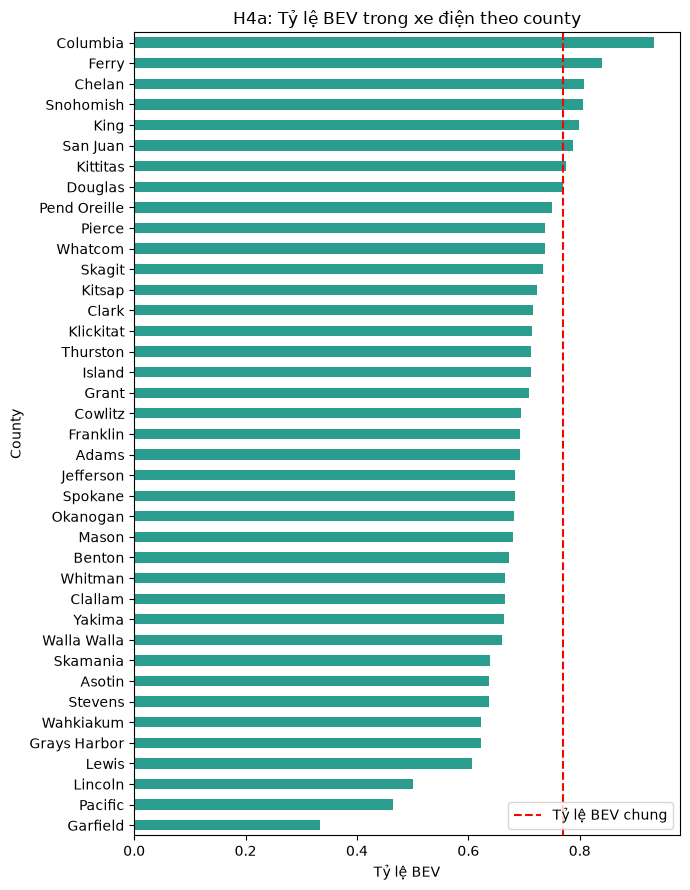

In [4]:
tab = pd.crosstab(P[tp.COUNTY], P["Type"])
share = (tab["BEV"] / tab.sum(axis=1)).sort_values()
ax = share.plot.barh(figsize=(7, 9), color="#2a9d8f")
ax.axvline(P["Type"].eq("BEV").mean(), color="red", ls="--", label="Tỷ lệ BEV chung")
ax.set(title="H4a: Tỷ lệ BEV trong xe điện theo county", xlabel="Tỷ lệ BEV")
ax.legend()
plt.tight_layout()
plt.savefig(ROOT / "figures" / "H4a_bev_share_by_county.png", dpi=150)
plt.show()

## Dataset [H]: H4b

In [5]:
H = pd.read_csv(th.DATA_PATH, parse_dates=["Date"])
H["County"] = H["County"].str.strip()
print(f"{len(H):,} dòng | {H['Date'].nunique()} tháng ({H['Date'].min():%m/%Y} - {H['Date'].max():%m/%Y})")
rows_h = []
th.run_month(H, H["Date"].max(), rows_h)
th.run_month(H, H["Date"].min(), rows_h)

6,474 dòng | 83 tháng (01/2017 - 11/2023)
[H4b 11/2023] 39 county x 2 | n=5,954,054 | chi2=72,265.8 dof=38 p=0 | Cramér's V=0.110 | min E=59.4 | tỷ lệ EV chung=2.678% -> Bác bỏ H0
  Tỷ lệ EV thấp nhất: {'Garfield': '0.14%', 'Adams': '0.25%', 'Columbia': '0.31%'}
  Tỷ lệ EV cao nhất: {'Snohomish': '2.92%', 'San Juan': '4.42%', 'King': '5.45%'}
[H4b 01/2017] 39 county x 2 | n=5,940,783 | chi2=11,788.7 dof=38 p=0 | Cramér's V=0.045 | min E=8.2 | tỷ lệ EV chung=0.367% -> Bác bỏ H0
  Tỷ lệ EV thấp nhất: {'Garfield': '0.00%', 'Adams': '0.01%', 'Wahkiakum': '0.02%'}
  Tỷ lệ EV cao nhất: {'Jefferson': '0.42%', 'San Juan': '0.60%', 'King': '0.78%'}


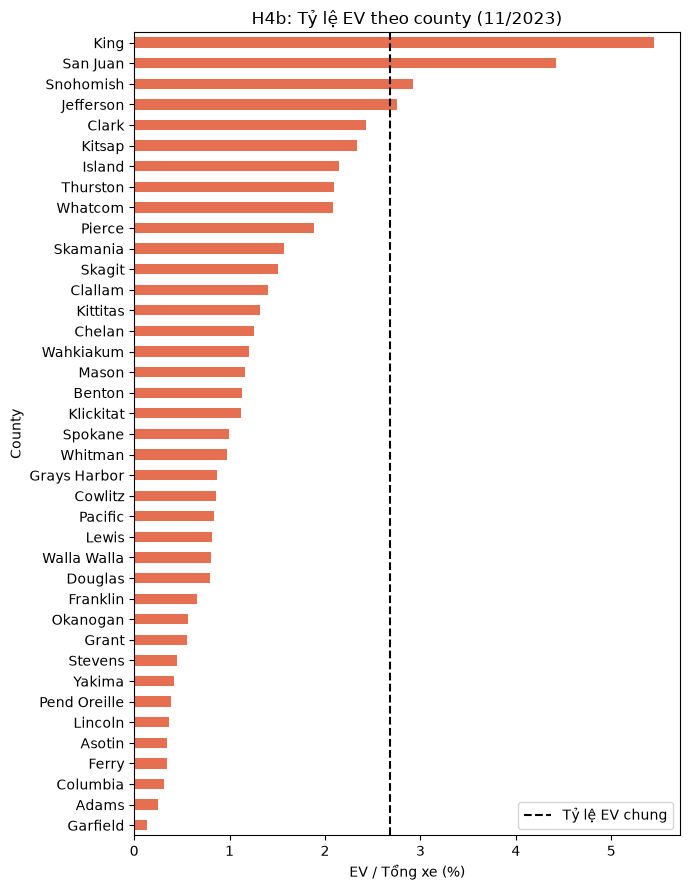

In [6]:
last = H[H["Date"] == H["Date"].max()].groupby("County")[["Electric Vehicle (EV) Total", "Total Vehicles"]].sum()
rate = (last.iloc[:, 0] / last.iloc[:, 1] * 100).sort_values()
ax = rate.plot.barh(figsize=(7, 9), color="#e76f51")
ax.axvline(last.iloc[:, 0].sum() / last.iloc[:, 1].sum() * 100, color="black", ls="--", label="Tỷ lệ EV chung")
ax.set(title=f"H4b: Tỷ lệ EV theo county ({H['Date'].max():%m/%Y})", xlabel="EV / Tổng xe (%)")
ax.legend()
plt.tight_layout()
plt.savefig(ROOT / "figures" / "H4b_ev_rate_by_county.png", dpi=150)
plt.show()

## Bảng tổng hợp kết quả

In [7]:
summary = pd.DataFrame(tp.rows + rows_h)
out = ROOT / "results" / "hypothesis_summary.csv"
summary.to_csv(out, index=False, encoding="utf-8-sig")
summary

,test,n,statistic,p_value,effect_size,effect_name,extra,decision
0,"H1 Mann-Whitney U (chính, toàn mẫu có Range)",77857,1.446940e+09,0.000000e+00,0.991147,rank-biserial,CLES=0.996,Bác bỏ H0
1,"H1 Mann-Whitney U (độ nhạy, Model Year<=2020)",65779,8.950288e+08,0.000000e+00,0.986172,rank-biserial,CLES=0.993,Bác bỏ H0
2,"H2 Spearman (chính, toàn mẫu)",77857,9.008592e-02,5.508505e-140,0.090086,|rho|,,Bác bỏ H0
3,H2 Spearman (BEV),46806,7.797733e-01,0.000000e+00,0.779773,|rho|,,Bác bỏ H0
4,H2 Spearman (PHEV),31051,3.553657e-02,3.758784e-10,0.035537,|rho|,,Bác bỏ H0
5,"H3 chi-square (chính 2x2, bỏ unknown)",77858,3.216589e+04,0.000000e+00,0.642756,Cramer's V,dof=1; minE=6690.4,Bác bỏ H0
6,"H3 chi-square (độ nhạy 2x3, giữ unknown)",134726,7.295720e+04,0.000000e+00,0.735882,Cramer's V,dof=2; minE=3866.3,Bác bỏ H0
7,H4a chi-square (39 county),134726,1.623496e+03,0.000000e+00,0.109774,Cramer's V,dof=38; minE=0.7,Bác bỏ H0
8,"H4a chi-square (độ nhạy, bỏ county < 30 xe (36...",134683,1.617202e+03,0.000000e+00,0.109579,Cramer's V,dof=35; minE=7.4,Bác bỏ H0
9,H4b chi-square (11/2023),5954054,7.226576e+04,0.000000e+00,0.110169,Cramer's V,dof=38; minE=59.4,Bác bỏ H0
